# 3 - Augment the dataset


In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").is_file():
    if ROOT.parent == ROOT:
        raise RuntimeError("run this notebook from inside the repository")
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
print("repo root:", ROOT)
print("python:  ", sys.version.split()[0], "->", sys.executable)

repo root: /Users/hasan.zanouzi/Documents/perception-decision-execution-feedback
python:   3.14.4 -> /Users/hasan.zanouzi/Documents/perception-decision-execution-feedback/venv/bin/python3.14


In [2]:
import json

from IPython.display import Image, display

from perception.dataset import augment_dataset

`configs/augmentation.json` is the reproducible source of truth for `fliplr`/`zoom_max`/`seed`.
`DATASET_ROOT` is mutated in place — `OVERWRITE = True` re-runs augmentation from scratch (the
function is otherwise a no-op if `augmentation_report.json` already exists in the dataset root).

In [3]:
DATASET_ROOT = ROOT / "datasets/animalai_merged"
AUGMENTATION_CONFIG = ROOT / "configs/augmentation.json"
OVERWRITE = False

augmentation_config = json.loads(AUGMENTATION_CONFIG.read_text())
print(json.dumps(augmentation_config, indent=2, sort_keys=True))

if not (DATASET_ROOT / "data.yaml").is_file():
    raise FileNotFoundError(f"{DATASET_ROOT} missing — run notebook 02 first")

{
  "fliplr": true,
  "seed": 20260725,
  "zoom_max": 1.3
}


In [4]:
report = augment_dataset(
    DATASET_ROOT,
    fliplr=augmentation_config["fliplr"],
    zoom_max=augmentation_config["zoom_max"],
    seed=augmentation_config["seed"],
    overwrite=OVERWRITE,
)
print(json.dumps(report, indent=2, sort_keys=True))

{
  "objects_dropped": 14969,
  "objects_kept": 55519,
  "seed": 20260725,
  "source_frames": 14954,
  "variants_added": {
    "fliplr": 14954,
    "zoom": 14954
  },
  "zoom_max": 1.3
}


original: images/train/curriculum__000000.png - 1 objects


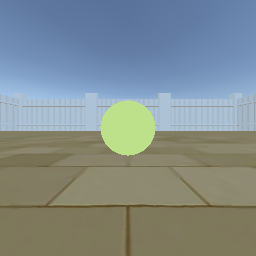

  fliplr: 1 objects kept


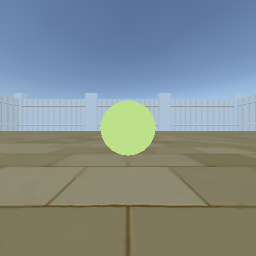

  zoom: 1 objects kept


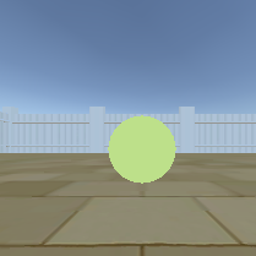

original: images/train/curriculum__000001.png - 1 objects


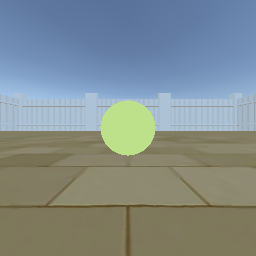

  fliplr: 1 objects kept


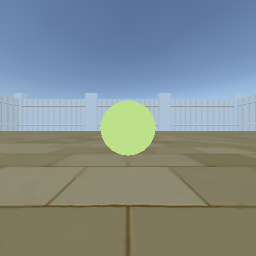

  zoom: 1 objects kept


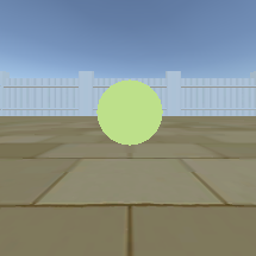

In [5]:
train_metadata = DATASET_ROOT / "metadata/train.jsonl"
records = [
    json.loads(line)
    for line in train_metadata.read_text(encoding="utf-8").splitlines()
    if line.strip()
]
originals = [record for record in records if not record.get("augmented")]
by_source_image = {}
for record in records:
    if record.get("augmented"):
        by_source_image.setdefault(record["image"].split("__")[0], []).append(record)

for original in originals[:2]:
    stem = original["image"].rsplit(".", 1)[0]
    print("original:", original["image"], "-", len(original["objects"]), "objects")
    display(Image(filename=str(DATASET_ROOT / original["image"])))
    for suffix in ("fliplr", "zoom"):
        variant_image = f"{stem}__{suffix}.png"
        variant = next(
            (record for record in records if record["image"] == variant_image), None
        )
        if variant is None:
            continue
        print(f"  {suffix}: {len(variant['objects'])} objects kept")
        display(Image(filename=str(DATASET_ROOT / variant["image"])))